# 02. Data quality assessment

Phase 1, task 1.4.3. First quality checks on the pulled data, computed from `data/raw/`. Findings are written up in `docs/datasets/data_quality.md`. This is a first pass: no records are changed, flagged or removed here, and no imputation is applied. Cleaning rules belong to Phase 2.

The notebook needs `data/raw/` (see notebook 01 for the download commands) and runs offline.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

## 1. US Diplomatic Post PM2.5 (reference-grade)

The main series. Checks: timestamp integrity, empty values, coverage by year and month, gaps, zeros, extremes, stuck values.

In [2]:
raw = pd.read_csv(
    RAW / "openaq" / "us_embassy_pm25_hourly.csv", parse_dates=["datetime_utc"]
)
raw["t"] = raw["datetime_utc"].dt.tz_localize(None)
checks = {
    "rows": len(raw),
    "first": raw["t"].min(),
    "last": raw["t"].max(),
    "timestamps unique": raw["t"].is_unique,
    "timestamps increasing": raw["t"].is_monotonic_increasing,
    "timestamps not on the hour": int((raw["t"].dt.minute != 0).sum()),
    "empty values": int(raw["value"].isna().sum()),
    "empty share": round(raw["value"].isna().mean(), 3),
    "whole-number values only": bool((raw["value"].dropna() % 1 == 0).all()),
    "percent_complete values": sorted(raw["percent_complete"].unique().tolist()),
}
pd.Series(checks)

rows                                        51492
first                         2018-11-27 21:00:00
last                          2025-03-04 11:00:00
timestamps unique                            True
timestamps increasing                        True
timestamps not on the hour                      0
empty values                                 7411
empty share                                 0.144
whole-number values only                     True
percent_complete values                   [100.0]
dtype: object

In [3]:
pm = raw.dropna(subset=["value"]).set_index("t")["value"]
full = pd.date_range(pm.index.min(), pm.index.max(), freq="h")
series = pm.reindex(full)
print(f"span {len(full)} h, valid {pm.size} h, valid share {pm.size / len(full):.3f}")

by_year = pd.DataFrame(
    {
        "rows in file": raw.groupby(raw["t"].dt.year).size(),
        "empty values": raw[raw["value"].isna()].groupby(raw["t"].dt.year).size(),
        "valid share of year": series.notna()
        .groupby(series.index.year)
        .mean()
        .round(2),
    }
).fillna(0)
by_year

span 54765 h, valid 44081 h, valid share 0.805


,rows in file,empty values,valid share of year
2018,743,130,0.75
2019,8380,1521,0.78
2020,8239,351,0.90
2021,7951,552,0.84
2022,8440,3107,0.61
2023,7478,707,0.77
2024,8761,857,0.90
2025,1500,186,0.98


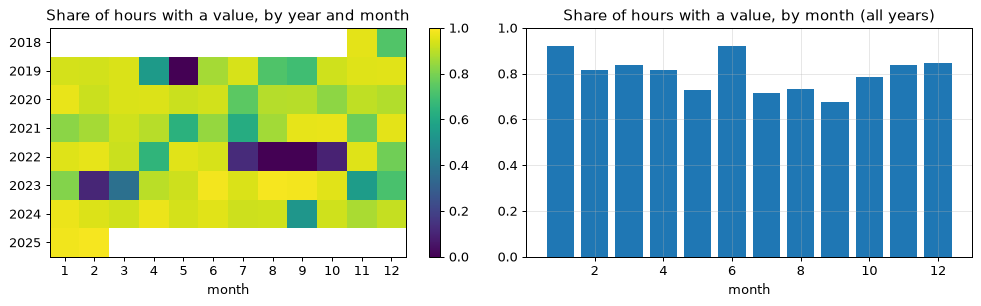

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
share = series.notna().groupby([series.index.year, series.index.month]).mean().unstack()
im = axes[0].imshow(share.to_numpy(), aspect="auto", cmap="viridis", vmin=0, vmax=1)
axes[0].set_xticks(range(12), range(1, 13))
axes[0].set_yticks(range(len(share)), share.index)
axes[0].set_title("Share of hours with a value, by year and month")
axes[0].set_xlabel("month")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0])
share_month = series.notna().groupby(series.index.month).mean()
axes[1].bar(share_month.index, share_month.to_numpy())
axes[1].set_ylim(0, 1)
axes[1].set_title("Share of hours with a value, by month (all years)")
axes[1].set_xlabel("month")
plt.tight_layout()

In [5]:
# Gap lengths: runs of consecutive missing hours inside the span.
missing = series.isna().astype(int)
runs = missing.groupby((missing.diff() != 0).cumsum()).agg(["first", "size"])
gaps = runs[runs["first"] == 1]["size"]
summary = pd.DataFrame(
    {
        "gaps": [(gaps >= n).sum() for n in (1, 6, 24, 168)],
        "hours inside them": [gaps[gaps >= n].sum() for n in (1, 6, 24, 168)],
    },
    index=["1 h or longer", "6 h or longer", "24 h or longer", "7 days or longer"],
)
print(
    "gap length quantiles (hours):", gaps.quantile([0.5, 0.9, 0.99]).round(0).to_dict()
)
longest = gaps.sort_values(ascending=False).head(5)
starts = [series.index[(missing.diff() != 0).cumsum() == i][0] for i in longest.index]
print("longest gaps:", list(zip(starts, longest.to_numpy())))
summary

gap length quantiles (hours): {0.5: 1.0, 0.9: 24.0, 0.99: 210.0}
longest gaps: [(Timestamp('2022-07-05 01:00:00'), np.int64(2783)), (Timestamp('2019-04-19 06:00:00'), np.int64(1086)), (Timestamp('2023-02-16 00:00:00'), np.int64(744)), (Timestamp('2024-09-12 04:00:00'), np.int64(321)), (Timestamp('2023-11-15 19:00:00'), np.int64(307))]


,gaps,hours inside them
1 h or longer,694,10684
6 h or longer,137,9888
24 h or longer,91,9419
7 days or longer,8,6019


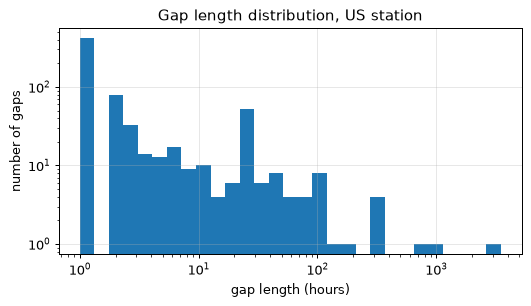

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(gaps, bins=np.logspace(0, np.log10(gaps.max()) + 0.1, 30))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("gap length (hours)")
ax.set_ylabel("number of gaps")
ax.set_title("Gap length distribution, US station")
plt.tight_layout()

In [7]:
# Values: zeros, extremes, stuck readings, abrupt changes.
zeros = pm[pm == 0]
print(
    "zeros by year:",
    zeros.groupby(zeros.index.year).size().to_dict(),
    "| total",
    len(zeros),
)
print(
    "above 300:",
    int((pm > 300).sum()),
    "| above 500:",
    int((pm > 500).sum()),
    "| max:",
    pm.max(),
)
print(
    "hours above 500 ug/m3, with the 3 hours before and after (missing shown as NaN):"
)
for t in pm[pm > 500].index:
    window = series.loc[t - pd.Timedelta(hours=3) : t + pd.Timedelta(hours=3)]
    print(t, window.round(0).tolist())

same_run = (pm.diff() != 0).cumsum()
run_lengths = pm.groupby(same_run).size()
print("\nlongest run of identical consecutive values:", int(run_lengths.max()))
adjacent = pm.index.to_series().diff() == pd.Timedelta(hours=1)
jumps = pm.diff()[adjacent].abs()
print("hourly changes above 100 ug/m3:", int((jumps > 100).sum()))

zeros by year: {2018: 1, 2019: 3, 2022: 1, 2023: 4, 2024: 69} | total 78
above 300: 84 | above 500: 16 | max: 978.0
hours above 500 ug/m3, with the 3 hours before and after (missing shown as NaN):
2019-06-26 03:00:00 [27.0, 26.0, 56.0, 966.0, nan, 97.0, 65.0]
2021-11-04 23:00:00 [nan, nan, nan, 923.0, nan, nan, nan]
2021-11-05 10:00:00 [nan, nan, nan, 978.0, 903.0, 872.0, 763.0]
2021-11-05 11:00:00 [nan, nan, 978.0, 903.0, 872.0, 763.0, 669.0]
2021-11-05 12:00:00 [nan, 978.0, 903.0, 872.0, 763.0, 669.0, 641.0]
2021-11-05 13:00:00 [978.0, 903.0, 872.0, 763.0, 669.0, 641.0, 406.0]
2021-11-05 14:00:00 [903.0, 872.0, 763.0, 669.0, 641.0, 406.0, 332.0]
2021-11-05 15:00:00 [872.0, 763.0, 669.0, 641.0, 406.0, 332.0, 369.0]
2021-11-06 04:00:00 [439.0, 376.0, 497.0, 725.0, 675.0, 642.0, 478.0]
2021-11-06 05:00:00 [376.0, 497.0, 725.0, 675.0, 642.0, 478.0, 488.0]
2021-11-06 06:00:00 [497.0, 725.0, 675.0, 642.0, 478.0, 488.0, 355.0]
2023-04-26 05:00:00 [20.0, 13.0, 17.0, 857.0, 857.0, nan, 20.0]


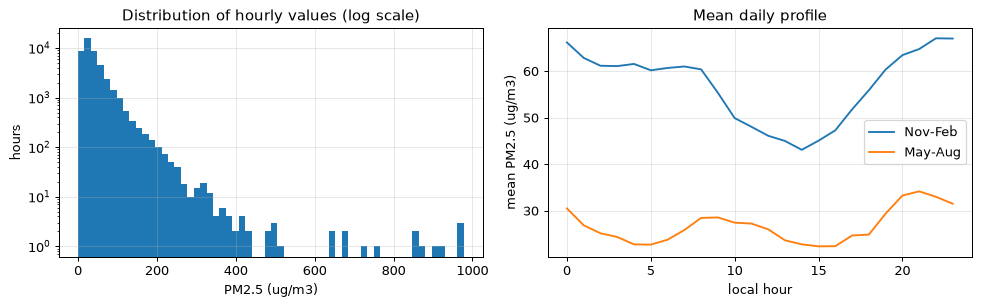

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(pm, bins=60)
axes[0].set_yscale("log")
axes[0].set_xlabel("PM2.5 (ug/m3)")
axes[0].set_ylabel("hours")
axes[0].set_title("Distribution of hourly values (log scale)")
local = pm.copy()
local.index = local.index + pd.Timedelta(hours=5)  # Asia/Tashkent
winter = local[local.index.month.isin([11, 12, 1, 2])]
summer = local[local.index.month.isin([5, 6, 7, 8])]
axes[1].plot(winter.groupby(winter.index.hour).mean(), label="Nov-Feb")
axes[1].plot(summer.groupby(summer.index.hour).mean(), label="May-Aug")
axes[1].set_xlabel("local hour")
axes[1].set_ylabel("mean PM2.5 (ug/m3)")
axes[1].set_title("Mean daily profile")
axes[1].legend()
plt.tight_layout()

In [9]:
# Daily means need at least 18 observed hours of the local day.
local_series = series.copy()
local_series.index = local_series.index + pd.Timedelta(hours=5)
counts = local_series.groupby(local_series.index.floor("D")).count()
print(
    "local days in span:",
    len(counts),
    "| with >= 18 hours:",
    int((counts >= 18).sum()),
    "| share:",
    round(float((counts >= 18).mean()), 3),
)
counts.groupby(counts.index.year).apply(lambda c: (c >= 18).mean()).round(2)

local days in span: 2282 | with >= 18 hours: 1824 | share: 0.799


2018    0.68
2019    0.77
2020    0.88
2021    0.82
2022    0.60
2023    0.78
2024    0.92
2025    1.00
Name: value, dtype: float64

## 2. Sputnik-4 low-cost sensor

In [10]:
frames = {
    name: pd.read_csv(
        RAW / "openaq" / f"sputnik4_{name}_hourly.csv", parse_dates=["datetime_utc"]
    ).set_index("datetime_utc")["value"]
    for name in ("pm25", "humidity", "temperature")
}
sp = pd.DataFrame(frames)
print(len(sp), "rows,", sp.index.min(), "to", sp.index.max())
step = sp.index.to_series().diff()
print(
    "largest time step:",
    step.max(),
    "| steps longer than 1 h:",
    int((step > pd.Timedelta(hours=1)).sum()),
)
print("empty values:", sp.isna().sum().to_dict())
sp.describe().round(1)

3277 rows, 2025-06-29 18:00:00+00:00 to 2026-01-19 16:00:00+00:00
largest time step: 63 days 17:00:00 | steps longer than 1 h: 34
empty values: {'pm25': 0, 'humidity': 0, 'temperature': 0}


,pm25,humidity,temperature
count,3277.0,3277.0,3277.0
mean,61.7,36.8,17.8
std,50.0,10.6,6.4
min,0.0,13.7,5.4
25%,29.8,28.3,12.7
50%,49.4,35.8,17.0
75%,78.4,45.1,22.5
max,298.0,63.4,37.9


In [11]:
# Relationship between humidity and PM2.5 on this sensor (association only).
valid = sp.dropna()
print(
    "Spearman correlation PM2.5 vs humidity:",
    round(valid["pm25"].corr(valid["humidity"], method="spearman"), 2),
)
valid.assign(humidity_bin=pd.cut(valid["humidity"], [0, 30, 40, 50, 100])).groupby(
    "humidity_bin", observed=True
)["pm25"].agg(["count", "mean", "median"]).round(1)

Spearman correlation PM2.5 vs humidity: 0.37


,count,mean,median
humidity_bin,,,
"(0, 30]",1014,36.1,33.0
"(30, 40]",1058,67.7,54.4
"(40, 50]",736,91.1,69.4
"(50, 100]",469,57.7,55.7


## 3. Mendeley TIIAME station

In [12]:
m = pd.read_csv(RAW / "mendeley_tashkent" / "all_sensor.csv")
m["t"] = pd.to_datetime(m["Date"] + " " + m["Time"], format="%m/%d/%Y %H:%M:%S")
print(len(m), "rows,", m["t"].min(), "to", m["t"].max(), "(local time)")
print(
    "duplicate timestamps:",
    int(m["t"].duplicated().sum()),
    "| empty cells:",
    int(m.isna().sum().sum()),
)
step = m["t"].diff()
print(
    "median step:",
    step.median(),
    "| steps over 31 min:",
    int((step > pd.Timedelta(minutes=31)).sum()),
    "| longest gap:",
    step.max(),
)
print(
    "PM2.5 identical to PM10 in",
    round(float((m["PM25/ug/m3"] == m["PM10/ug/m3"]).mean()), 3),
    "of rows, to TSP in",
    round(float((m["PM25/ug/m3"] == m["tsp/ug/m3"]).mean()), 3),
)
m["PM25/ug/m3"].describe().round(1)

9546 rows, 2024-02-26 11:22:19 to 2024-09-18 14:47:24 (local time)
duplicate timestamps: 0 | empty cells: 0
median step: 0 days 00:30:00 | steps over 31 min: 27 | longest gap: 2 days 08:11:46
PM2.5 identical to PM10 in 0.081 of rows, to TSP in 0.078


count    9546.0
mean        7.5
std         8.3
min         0.0
25%         2.0
50%         5.0
75%        10.0
max       119.0
Name: PM25/ug/m3, dtype: float64

## 4. Open-Meteo ERA5 and archived forecasts

In [13]:
era = pd.read_csv(
    RAW / "openmeteo" / "era5_tashkent_hourly.csv", parse_dates=["datetime_utc"]
).set_index("datetime_utc")
extra = pd.read_csv(
    RAW / "openmeteo" / "era5_extra_tashkent_hourly.csv", parse_dates=["datetime_utc"]
).set_index("datetime_utc")
print("ERA5 core:", len(era), "rows, missing cells:", int(era.isna().sum().sum()))
steps = era.index.to_series().diff().dropna()
print("regular hourly steps:", bool((steps == pd.Timedelta(hours=1)).all()))
print("ERA5 extra missing hours:", extra.isna().sum().to_dict())
blh_gap = extra.index[extra["boundary_layer_height"].isna()]
print("boundary layer height missing from", blh_gap.min(), "to", blh_gap.max())
era.describe().round(1).T[["min", "50%", "max"]]

ERA5 core: 70368 rows, missing cells: 0
regular hourly steps: True
ERA5 extra missing hours: {'boundary_layer_height': 4368, 'shortwave_radiation': 0, 'vapour_pressure_deficit': 0, 'pressure_msl': 0, 'snow_depth': 0}
boundary layer height missing from 2024-01-01 00:00:00+00:00 to 2024-06-30 23:00:00+00:00


,min,50%,max
temperature_2m,-26.3,15.4,44.6
relative_humidity_2m,6.0,50.0,100.0
dew_point_2m,-29.7,3.9,23.2
precipitation,0.0,0.0,11.5
surface_pressure,944.8,962.4,993.1
cloud_cover,0.0,18.0,100.0
wind_speed_10m,0.0,7.5,34.3
wind_direction_10m,0.0,145.0,360.0
wind_gusts_10m,1.1,16.9,65.2


In [14]:
fc = pd.read_csv(
    RAW / "openmeteo" / "forecast_previous_runs_hourly.csv",
    parse_dates=["datetime_utc"],
).set_index("datetime_utc")
print("forecast file:", len(fc), "rows,", fc.index.min(), "to", fc.index.max())
share_empty = fc.isna().mean().round(3)
print("empty share per column: min", share_empty.min(), "max", share_empty.max())

# Forecast against ERA5 on the same hours (issued 2 days ahead).
both = fc.join(era, how="inner")  # column names do not overlap
rows = []
for v in (
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "surface_pressure",
    "cloud_cover",
):
    x = both[[f"{v}_previous_day2", v]].dropna()
    err = x.iloc[:, 0] - x.iloc[:, 1]
    rows.append(
        {
            "variable": v,
            "bias (fc - era5)": err.mean(),
            "MAE": err.abs().mean(),
            "corr": x.corr().iloc[0, 1],
        }
    )
pd.DataFrame(rows).set_index("variable").round(2)

forecast file: 9792 rows, 2024-01-19 00:00:00+00:00 to 2025-03-01 23:00:00+00:00
empty share per column: min 0.004 max 0.009


,bias (fc - era5),MAE,corr
variable,,,
temperature_2m,0.93,1.71,0.99
relative_humidity_2m,-1.40,9.12,0.87
wind_speed_10m,-2.52,3.52,0.45
surface_pressure,0.42,0.91,0.99
cloud_cover,5.52,19.69,0.70


## 5. Data availability across sources

Hours with a PM2.5 value in the US series and hours with archived forecasts, by month. This shows where fair forecast-weather evaluation is possible.

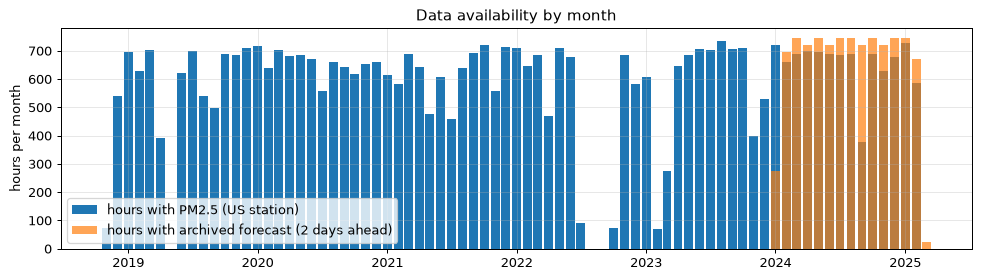

In [15]:
months = pd.period_range("2018-11", "2025-03", freq="M")
pm_hours = (
    series.notna()
    .groupby(series.index.to_period("M"))
    .sum()
    .reindex(months, fill_value=0)
)
fc_naive = fc.copy()
fc_naive.index = fc_naive.index.tz_localize(None)
fc_hours = (
    fc_naive["temperature_2m_previous_day2"]
    .notna()
    .groupby(fc_naive.index.to_period("M"))
    .sum()
    .reindex(months, fill_value=0)
)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(
    months.to_timestamp(),
    pm_hours.to_numpy(),
    width=25,
    label="hours with PM2.5 (US station)",
)
ax.bar(
    months.to_timestamp(),
    fc_hours.to_numpy(),
    width=25,
    color="tab:orange",
    alpha=0.7,
    label="hours with archived forecast (2 days ahead)",
)
ax.set_ylabel("hours per month")
ax.legend(loc="lower left")
ax.set_title("Data availability by month")
plt.tight_layout()

## 6. Time alignment between OpenAQ and Open-Meteo

OpenAQ labels each hourly value with the start of the hour, and Open-Meteo labels values with the hour (state variables are instantaneous at that time). To check that the two labels line up, the Sputnik-4 temperature and humidity (OpenAQ) are compared with ERA5 at lags of -3 to +3 hours. The comparison uses hourly deviations from each day's mean, so it measures the timing of the daily cycle, over the period when the sensor reports continuously (from September 2025). The two places are about 18 km apart, so the match is approximate. A lag of 0 means the labels agree.

In [16]:
sp_t = pd.read_csv(
    RAW / "openaq" / "sputnik4_temperature_hourly.csv", parse_dates=["datetime_utc"]
).set_index("datetime_utc")["value"]
sp_h = pd.read_csv(
    RAW / "openaq" / "sputnik4_humidity_hourly.csv", parse_dates=["datetime_utc"]
).set_index("datetime_utc")["value"]
pairs = {
    "temperature": (sp_t, "temperature_2m"),
    "humidity": (sp_h, "relative_humidity_2m"),
}
rows = []
for name, (sensor, era_col) in pairs.items():
    sensor = sensor[sensor.index >= "2025-09-01"]
    for lag in range(-3, 4):
        era_shifted = (
            era[era_col].shift(-lag).reindex(sensor.index)
        )  # ERA5 at label + lag
        x = pd.concat([sensor, era_shifted], axis=1).dropna()
        anomaly = x - x.groupby(x.index.floor("D")).transform("mean")
        rows.append(
            {"variable": name, "lag (h)": lag, "correlation": anomaly.corr().iloc[0, 1]}
        )
table = (
    pd.DataFrame(rows)
    .pivot(index="lag (h)", columns="variable", values="correlation")
    .round(3)
)
print(table.to_string())
for name in pairs:
    c = table[name]
    # Parabola through the best lag and its two neighbours gives the fractional offset.
    k = int(c.idxmax())
    offset = k + 0.5 * (c[k - 1] - c[k + 1]) / (c[k - 1] - 2 * c[k] + c[k + 1])
    print(f"{name}: best lag {k} h, interpolated offset {offset:+.2f} h")

variable  humidity  temperature
lag (h)                        
-3           0.610        0.592
-2           0.720        0.763
-1           0.791        0.886
 0           0.809        0.940
 1           0.759        0.911
 2           0.649        0.801
 3           0.504        0.632
temperature: best lag 0 h, interpolated offset +0.15 h
humidity: best lag 0 h, interpolated offset -0.24 h


## 7. Findings and open issues

The numbers are in the tables above and written up in `docs/datasets/data_quality.md`.

- The US station is usable but uneven: coverage varies by year (lowest in 2022, with a gap of about four months), and some months are thinly covered.
- Zeros, extreme values and abrupt changes are present and were kept. Most hours above 500 ug/m3 belong to a smooth episode on 4 to 6 November 2021. Three events jump from below 60 to 860-970 ug/m3 within one hour and fall straight back (2019-06-26, 2023-04-26 with a repeated reading, 2024-07-18), which look like sensor artefacts. None are verified against another source.
- Only the US series spans several winters. The Sputnik-4 series is short and the Mendeley series has no winter.
- ERA5 core weather is complete. Boundary layer height has a six-month gap in 2024.
- Archived forecasts overlap the PM2.5 data only from 2024-01-19 to 2025-02-25.

The OpenAQ and Open-Meteo labels agree to within about a quarter of an hour (interpolated offsets +0.15 h for temperature and -0.24 h for humidity), so no shift is applied. Open: reason for the empty hourly values, validation of extreme values, and the effect of humidity on the low-cost sensor.